# 10 — Deep Learning with PyTorch (Part 2, Phase 4)

Train a tabular multilayer perceptron for **interest-rate regression** and **three-class repayment classification**, using the original tasks, classes and frozen chronological partitions. Reusable classes are in `Python/deep_learning.py` and `Python/deep_learning_experiments.py`.

Train through December 2014; external development validation is January 2015–December 2016; final test starts January 2017 and remains unread. No class merging, random temporal split, grade extension, or new joint-income predictor is introduced. Prior validation findings motivated numerical conditioning, so these are development comparisons rather than an independent final assessment.

In [1]:
import sys, json, platform
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import sklearn
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve, average_precision_score
from IPython.display import display, Markdown

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from Python.deep_learning import NeuralConfig, NeuralModelBundle
from Python.deep_learning_experiments import NeuralExperimentRunner
OUT = PROJECT_ROOT / 'outputs' / 'deep_learning'
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
config = NeuralConfig()
runner = NeuralExperimentRunner(PROJECT_ROOT, OUT, config)
metadata = {'configuration': config.to_dict(), 'split': runner.setup.split_config,
            'predictor_plan': runner.setup.predictor_plan, 'python': platform.python_version(),
            'numpy': np.__version__, 'sklearn': sklearn.__version__, 'torch': str(torch.__version__),
            'device': 'CPU, deterministic algorithms, two threads',
            'classes': {'0': 'Good', '1': 'At risk', '2': 'Default'},
            'feature_policy': 'Original allowlists; training-fitted clipping/log1p before existing imputation/scaling/encoding',
            'stopping': 'Final unique month inside each training partition, followed by fresh complete-partition refit',
            'classification_sampling': 'None: every available training row retained',
            'regression_sampling': 'Seeded cap of 50,000 fitting rows; evaluation/stopping rows never sampled',
            'test_policy': 'No final test rows read',
            'validation_status': 'Prior audits informed numerical conditioning; development comparisons only'}
_ = (OUT / 'experiment_config.json').write_text(json.dumps(metadata, indent=2))
assert runner.setup.split_config['train_end'] == '2014-12'
assert runner.setup.split_config['val_end'] == '2016-12'
display(pd.Series(config.to_dict(), name='setting').to_frame())
started = perf_counter()
results = {}

,setting
hidden,"(128, 64)"
dropout,0.2
weight_decay,0.0001
batch_size,2048
prediction_batch_size,32768
max_epochs,60
patience,8
min_delta,0.0001
gradient_clip,5.0
threads,2


## 1. Architecture and justification

A feed-forward MLP is appropriate for the available fixed-width numeric and one-hot categorical tabular data. There is no complete event sequence to justify a recurrent model, and an image architecture or pretrained image network would not match these inputs.

Architecture: encoded input → **128 ReLU units → dropout 0.2 → 64 ReLU units → dropout 0.2 → linear output**. Regression has one output; classification has three logits. Classification trains directly with cross-entropy on logits and applies softmax only during inference. Regression standardizes its target using fitting-label mean/standard deviation, trains with MSE, and reverses that standardization when predicting rates in percentage points.

AdamW uses weight decay 0.0001, shuffled minibatches of 2,048, and gradient norm clipping at 5. Classification compares ordinary and inverse-frequency balanced cross-entropy, with weights derived from fitting labels only. Weighted losses are summed then divided by batch row count, preserving the global weighted objective rather than renormalizing by each random batch's weight sum. These weighted softmax scores are not automatically calibrated population risks.

The architecture is deliberately modest. Its additional flexibility does not supply missing independent At risk examples or repair the snapshot/follow-up support gap found in Notebook 09c.

## 2. Numerical treatment and leakage protection

Reuse the original per-task allowlists. Before imputation, learn 0.5–99.5% numeric clipping bounds on the current fitting rows. Apply log1p to the declared nonnegative skewed features, treating negative values for those log inputs as missing. Then use median numeric imputation, standardization, most-frequent categorical imputation, and one-hot encoding with unknown-category handling.

This explicitly declared treatment is motivated by the observed extreme income ratios and skewed inputs. It prevents unbounded numeric extrapolation of those inputs; it does not claim to repair joint-applicant semantics. No joint-income or grade field is added. All learned bounds, imputers, scales, category vocabularies, and target statistics are fitted independently for each training stage. Historical all-missing numeric fields follow the existing imputer drop policy. Save the fitted bounds and complete preprocessing with each model.

Because earlier models used different numeric treatments and sometimes different training sizes, the comparisons are practical experiment comparisons rather than a pure architecture-only ablation.

## 3. Chronological early stopping and declared budget

Retain the five original expanding-month CV folds, including the classification start through February 2014. Within each outer fitting partition, reserve only its **last unique month** for early stopping. Keep the whole month together. Fit preprocessing and regression target normalization on the preceding fitting rows only.

Both classification sides must contain all three classes. In the first classification fold, inner fitting has 13 At risk loans and the February 2014 stopping month has 20. A long arbitrary stopping tail would leave the fitting side without At risk examples, so this is checked explicitly.

After selecting the best epoch by inner stopping loss, fit a **fresh preprocessor and fresh network** on the whole outer fitting partition for exactly that many epochs. The outer fold is then scored once. Final development models follow the same procedure within the original training period: use December 2014 for stopping, then refit on all original training rows. External 2015–2016 validation never selects epochs.

For computational control, regression uses a reproducible cap of 50,000 fitting rows, separately for inner selection and outer refit; save those source positions. Classification retains every fitting row and all 611 At risk examples in final refits. Stopping/evaluation cohorts are complete.

Use at most **60 epochs**, patience **8**, and minimum stopping-loss improvement 0.0001. This revises Notebook 06's tentative upper budget of 100 epochs/patience 10 before the experiment. Select between two regression learning rates (0.001 and 0.0003) and two classification weight policies at rate 0.001. Primary seed 42 is used for five-fold selection: **20 CV experiments**, each with inner stopping and a fresh refit. Then train **three development seeds (42, 43, 44) per task**. Regression seed variability includes both subset and neural randomness; classification variability reflects initialization/dropout/minibatch order. No external-validation seed is selected as a winner.

In [2]:
plan = pd.DataFrame([{'task': task, 'parameters': json.dumps(parameters, sort_keys=True)}
                     for task in ['regression', 'classification'] for parameters in runner.candidates(task)])
plan.to_csv(OUT / 'candidate_plan.csv', index=False)
display(plan)

,task,parameters
0,regression,"{""class_weight"": ""none"", ""learning_rate"": 0.001}"
1,regression,"{""class_weight"": ""none"", ""learning_rate"": 0.0003}"
2,classification,"{""class_weight"": ""none"", ""learning_rate"": 0.001}"
3,classification,"{""class_weight"": ""balanced"", ""learning_rate"": ..."


## 4. Regression: training-CV selection and three development seeds

Select minimum mean fold RMSE, with parameter JSON order resolving exact ties. CV standard deviation reflects changing vintages and fitting sizes. Save the selection before scoring external validation. A 50,000-row cap is an explicit computational limitation; all 855,502 validation loans are evaluated.

In [3]:
results['regression'] = runner.run('regression')
display(results['regression'][1])
display(results['regression'][2].dropna(axis=1, how='all'))

/Users/goncalo.ramos/Mestrado/CD/projeto/Project_Ciencias_Dados/.venv/lib/python3.14/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['mort_acc' 'tot_cur_bal' 'tot_hi_cred_lim' 'bc_util' 'bc_open_to_buy'
 'mo_sin_old_rev_tl_op' 'num_actv_rev_tl' 'pct_tl_nvr_dlq' 'bc_pressure']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/goncalo.ramos/Mestrado/CD/projeto/Project_Ciencias_Dados/.venv/lib/python3.14/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['mort_acc' 'tot_cur_bal' 'tot_hi_cred_lim' 'bc_util' 'bc_open_to_buy'
 'mo_sin_old_rev_tl_op' 'num_actv_rev_tl' 'pct_tl_nvr_dlq' 'bc_pressure']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/goncalo.ramos/Mestrado/CD/projeto/Project_Ciencias_Dados/.venv/lib/python3.14/site-packages/sklearn/impute/_base.py:647: UserWarnin

MLP regression/inner/seed42: epoch 10, loss=0.4041, stopping=0.5051


MLP regression/inner/seed42: epoch 20, loss=0.2142, stopping=0.2698


MLP regression/inner/seed42: epoch 30, loss=0.1595, stopping=0.2458


MLP regression/inner/seed42: epoch 40, loss=0.1363, stopping=0.2442


MLP regression/refit/seed42: epoch 10, loss=0.3933


... (130 outputs left out)

MLP regression/refit/seed44: epoch 10, loss=0.4084


regression_validation_seed44_lr0.0003_none: selected 15 epochs; RMSE=3.607


,parameters,mean,std,count
0,"{""class_weight"": ""none"", ""learning_rate"": 0.0003}",2.548647,0.626443,5
1,"{""class_weight"": ""none"", ""learning_rate"": 0.001}",2.563057,0.622401,5


,task,partition,seed,parameters,n_train_available,n_train,n_evaluation,n_features,fit_predict_seconds,inner_available,inner_fitted,n_stopping,inner_end,stopping_start,stopping_end,selected_epochs,stopping_epochs_run,mae,rmse,r2
0,regression,validation,42,"{""class_weight"": ""none"", ""learning_rate"": 0.0003}",466345,50000,855502,103,2.770043,456038,50000,10307,2014-11-01 00:00:00,2014-12-01 00:00:00,2014-12-01 00:00:00,15,23,2.905340,3.602105,0.398605
1,regression,validation,43,"{""class_weight"": ""none"", ""learning_rate"": 0.0003}",466345,50000,855502,101,2.656606,456038,50000,10307,2014-11-01 00:00:00,2014-12-01 00:00:00,2014-12-01 00:00:00,14,22,2.863770,3.566475,0.410443
2,regression,validation,44,"{""class_weight"": ""none"", ""learning_rate"": 0.0003}",466345,50000,855502,104,2.744819,456038,50000,10307,2014-11-01 00:00:00,2014-12-01 00:00:00,2014-12-01 00:00:00,15,23,2.909141,3.607228,0.396893


## 5. Classification: keep all original classes and training examples

Select maximum mean fold macro F1, while reporting per-class average precision, precision and recall, and fixed review-budget metrics. Keep the original argmax decision rule in this model comparison; no thresholds are selected using external validation. The three output labels remain unchanged even if a selected configuration poorly detects one class. All 678,142 validation loans are evaluated.

In [4]:
results['classification'] = runner.run('classification')
display(results['classification'][1])
display(results['classification'][2].dropna(axis=1, how='all'))
elapsed = perf_counter() - started
_ = (OUT / 'execution_summary.json').write_text(json.dumps({'seconds': elapsed}, indent=2))
print(f'Experiment runtime: {elapsed / 60:.2f} minutes')

MLP classification/inner/seed42: epoch 10, loss=0.3999, stopping=0.4279


classification_cv_1_seed42_lr0.001_none: selected 2 epochs; macro F1=0.301


MLP classification/inner/seed42: epoch 10, loss=0.4367, stopping=89.4682


classification_cv_1_seed42_lr0.001_balanced: selected 2 epochs; macro F1=0.349


MLP classification/inner/seed42: epoch 10, loss=0.4033, stopping=0.4521


classification_cv_2_seed42_lr0.001_none: selected 8 epochs; macro F1=0.299


... (17 outputs left out)

classification_validation_seed44_lr0.001_balanced: selected 1 epochs; macro F1=0.366


,parameters,mean,std,count
0,"{""class_weight"": ""balanced"", ""learning_rate"": ...",0.348878,0.004047,5
1,"{""class_weight"": ""none"", ""learning_rate"": 0.001}",0.307052,0.009188,5


,task,partition,seed,parameters,n_train_available,n_train,n_evaluation,n_features,fit_predict_seconds,inner_available,...,precision_class_2,recall_class_2,ap_class_2,risk_prevalence,review_n,risk_precision_at_budget,risk_recall_at_budget,n_train_class_0,n_train_class_1,n_train_class_2
0,classification,validation,42,"{""class_weight"": ""balanced"", ""learning_rate"": ...",451671,451671,678142,113,10.436375,442270,...,0.332188,0.265168,0.287861,0.013996,6782,0.049543,0.035402,374560,611,76500
1,classification,validation,43,"{""class_weight"": ""balanced"", ""learning_rate"": ...",451671,451671,678142,113,8.904779,442270,...,0.321264,0.265209,0.281875,0.013996,6782,0.050133,0.035823,374560,611,76500
2,classification,validation,44,"{""class_weight"": ""balanced"", ""learning_rate"": ...",451671,451671,678142,113,9.013119,442270,...,0.296508,0.303556,0.264953,0.013996,6782,0.051312,0.036666,374560,611,76500


Experiment runtime: 2.43 minutes


## 6. Selected CV metrics, inner support, and external seed variability

Separate CV fold variability from final training-seed variability. Neither is a confidence interval on independent repeated future portfolios. All three seed scores are reported; they are not three independent validation cohorts.

Verify that every final classification refit retains all original rows and 611 At risk examples. The stopping cohort is inside the training period, and is reincorporated only in the fresh refit once the epoch count is fixed.

In [5]:
metric_names = ['mae', 'rmse', 'r2', 'accuracy', 'precision_macro', 'recall_macro', 'f1_macro',
                'precision_micro', 'recall_micro', 'f1_micro', 'auc_macro_ovr', 'auc_micro_ovr',
                'ap_class_1', 'precision_class_1', 'recall_class_1', 'ap_class_2', 'recall_class_2']
summary_rows, chosen_folds = [], []
for task, (cv, tuning, scores) in results.items():
    selected = json.loads((OUT / f'{task}_selection.json').read_text())['parameters']
    frame = cv[cv.parameters == json.dumps(selected, sort_keys=True)]
    assert len(frame) == 5
    chosen_folds.append(frame)
    for metric in metric_names:
        if metric in frame:
            summary_rows.append({'task': task, 'metric': metric, 'cv_mean': frame[metric].mean(),
                                 'cv_std': frame[metric].std(ddof=1),
                                 'validation_seed_mean': scores[metric].mean(),
                                 'validation_seed_std': scores[metric].std(ddof=1)})
    assert (pd.to_datetime(frame.inner_end) < pd.to_datetime(frame.stopping_start)).all()
cv_summary = pd.DataFrame(summary_rows)
cv_summary.to_csv(OUT / 'selected_metric_summary.csv', index=False)
chosen_folds = pd.concat(chosen_folds, ignore_index=True)
chosen_folds.to_csv(OUT / 'selected_cv_folds.csv', index=False)
display(cv_summary)
display(chosen_folds[['task', 'partition', 'inner_fitted', 'n_stopping', 'inner_end', 'stopping_start',
                      'n_train', 'n_evaluation', 'selected_epochs', 'stopping_epochs_run']])
class_scores = results['classification'][2]
assert class_scores.n_train.eq(451671).all()
assert class_scores.n_train_class_1.eq(611).all()
display(chosen_folds[chosen_folds.task == 'classification'][['partition', 'inner_class_1', 'stopping_class_1', 'n_train_class_1']])

,task,metric,cv_mean,cv_std,validation_seed_mean,validation_seed_std
0,regression,mae,1.987332,0.476399,2.892750,0.025169
1,regression,rmse,2.548647,0.626443,3.591936,0.022198
2,regression,r2,0.519852,0.215236,0.401980,0.007379
3,classification,accuracy,0.572339,0.019263,0.587017,0.017156
4,classification,precision_macro,0.389140,0.003347,0.404028,0.004017
5,classification,recall_macro,0.580317,0.018841,0.475529,0.001611
6,classification,f1_macro,0.348878,0.004047,0.370520,0.003934
7,classification,precision_micro,0.572339,0.019263,0.587017,0.017156
8,classification,recall_micro,0.572339,0.019263,0.587017,0.017156
9,classification,f1_micro,0.572339,0.019263,0.587017,0.017156


,task,partition,inner_fitted,n_stopping,inner_end,stopping_start,n_train,n_evaluation,selected_epochs,stopping_epochs_run
0,regression,cv_1,2355,57,2008-08-01 00:00:00,2008-09-01 00:00:00,2412,5865,60,60
1,regression,cv_2,7619,658,2009-11-01 00:00:00,2009-12-01 00:00:00,8277,16663,60,60
2,regression,cv_3,23492,1448,2011-02-01 00:00:00,2011-03-01 00:00:00,24940,36118,57,60
3,regression,cv_4,50000,3817,2012-05-01 00:00:00,2012-06-01 00:00:00,50000,125789,57,60
4,regression,cv_5,50000,12987,2013-08-01 00:00:00,2013-09-01 00:00:00,50000,279498,58,60
5,classification,cv_1,243584,15225,2014-01-01 00:00:00,2014-02-01 00:00:00,258809,34449,2,10
6,classification,cv_2,275039,18219,2014-03-01 00:00:00,2014-04-01 00:00:00,293258,34370,1,9
7,classification,cv_3,311394,16234,2014-05-01 00:00:00,2014-06-01 00:00:00,327628,45416,2,10
8,classification,cv_4,355253,17791,2014-07-01 00:00:00,2014-08-01 00:00:00,373044,46182,1,9
9,classification,cv_5,383033,36193,2014-09-01 00:00:00,2014-10-01 00:00:00,419226,32445,3,11


,partition,inner_class_1,stopping_class_1,n_train_class_1
5,cv_1,13.0,20.0,33.0
6,cv_2,69.0,47.0,116.0
7,cv_3,154.0,48.0,202.0
8,cv_4,280.0,60.0,340.0
9,cv_5,369.0,121.0,490.0


## 7. Learning curves and epoch selection

These plots show **inner** fitting/stopping histories, not external validation used to choose epochs. Training loss is accumulated with dropout active; stopping loss is evaluated without dropout. Loss magnitudes differ between ordinary and balanced CE, and standardized regression MSE is not percentage-point RMSE. The vertical line marks the chosen epoch. Fixed-epoch refit histories are saved separately.

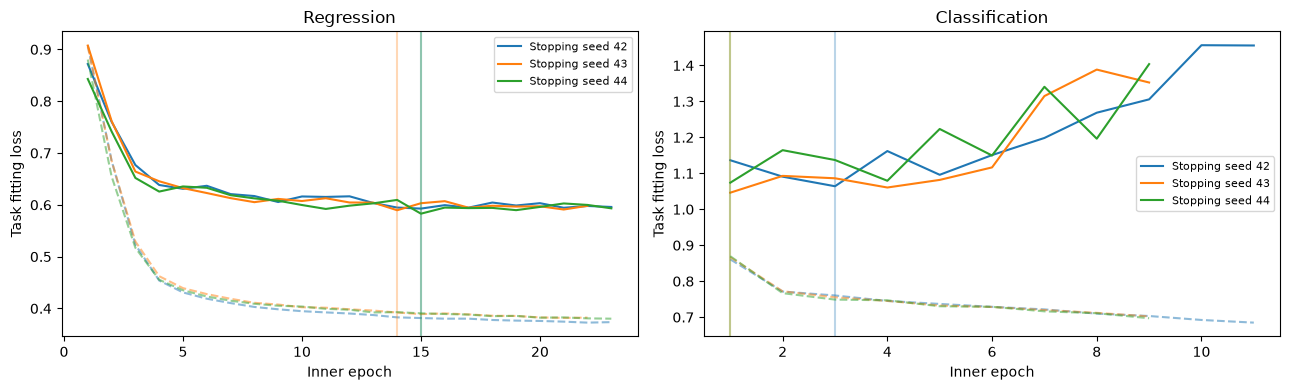

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, task in zip(axes, ['regression', 'classification']):
    for seed in config.final_seeds:
        row = results[task][2].query('seed == @seed').iloc[0]
        parameters = json.loads(row.parameters)
        key = f"{task}_validation_seed{seed}_lr{parameters['learning_rate']}_{parameters['class_weight']}"
        history = pd.read_csv(OUT / 'histories' / f'{key}_stopping.csv')
        line, = ax.plot(history.epoch, history.stopping_loss, label=f'Stopping seed {seed}')
        ax.plot(history.epoch, history.training_loss, '--', color=line.get_color(), alpha=.5)
        ax.axvline(row.selected_epochs, color=line.get_color(), alpha=.3)
    ax.set(title=task.title(), xlabel='Inner epoch', ylabel='Task fitting loss')
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / 'learning_curves.png', dpi=150)
plt.show()

## 8. Same-cohort comparisons with previous models

Verify targets and dates in identical order before comparing all final seeds with previous results. Numeric conditioning and regression training budgets differ, so small differences are not evidence of an isolated architecture effect. Earlier results are preserved, including Ridge's documented failure.

In [7]:
comparisons = {}
for task in ['regression', 'classification']:
    prior = pd.read_csv(PROJECT_ROOT / f'outputs/ensembles/{task}_comparison.csv')
    fresh = results[task][2].copy()
    fresh['model'] = 'pytorch_mlp'
    table = pd.concat([prior, fresh], ignore_index=True)
    assert table.n_evaluation.nunique() == 1
    table.to_csv(OUT / f'{task}_comparison.csv', index=False)
    comparisons[task] = table
    reference = pd.read_parquet(PROJECT_ROOT / f'outputs/ensembles/{task}_hist_gradient_boosting_validation_predictions.parquet')
    target = 'int_rate' if task == 'regression' else 'target_class'
    for seed in config.final_seeds:
        frame = pd.read_parquet(OUT / f'{task}_seed{seed}_validation_predictions.parquet')
        np.testing.assert_array_equal(frame[target], reference[target])
        np.testing.assert_array_equal(frame.issue_d, reference.issue_d)
    metrics = ['mae', 'rmse', 'r2'] if task == 'regression' else ['accuracy', 'f1_macro', 'auc_macro_ovr']
    display(Markdown(f'### {task}'))
    columns = ['model', 'n_train', 'n_evaluation'] + metrics
    display(table[columns])

### regression

,model,n_train,n_evaluation,mae,rmse,r2
0,knn_scratch,10000,855502,2.978551,3.768190,0.341868
1,dummy_sample_mean,10000,855502,3.822251,4.740755,-0.041699
2,dummy_sample_median,10000,855502,3.788620,4.717786,-0.031630
3,dummy_mean,466345,855502,3.837982,4.752284,-0.046772
4,dummy_median,466345,855502,3.791029,4.719547,-0.032400
5,decision_tree,466345,855502,2.996727,3.734422,0.353611
6,ridge,466345,855502,3.163244,80.974286,-302.907580
7,hist_gradient_boosting,466345,855502,2.888858,3.588218,0.403233
8,random_forest,466345,855502,2.950886,3.659535,0.379275
9,pytorch_mlp,50000,855502,2.905340,3.602105,0.398605


### classification

,model,n_train,n_evaluation,accuracy,f1_macro,auc_macro_ovr
0,knn_scratch,10000,678142,0.763160,0.334668,0.565973
1,dummy_sample_prior,10000,678142,0.773577,0.290778,0.500000
2,dummy_most_frequent,451671,678142,0.773577,0.290778,0.500000
3,dummy_prior,451671,678142,0.773577,0.290778,0.500000
4,decision_tree,451671,678142,0.605854,0.389358,0.634361
5,logistic,451671,678142,0.591153,0.377292,0.657480
6,hist_gradient_boosting,451671,678142,0.666474,0.421880,0.696218
7,random_forest,451671,678142,0.638685,0.408874,0.675917
8,pytorch_mlp,451671,678142,0.600110,0.374096,0.657894
9,pytorch_mlp,451671,678142,0.593345,0.371160,0.657498


## 9. Regression residuals and vintage errors

Use primary seed 42 for descriptive plots, without choosing a seed on validation. Display sampling is seeded; all metrics use the complete validation cohort. Actual-minus-predicted residuals are in percentage points.

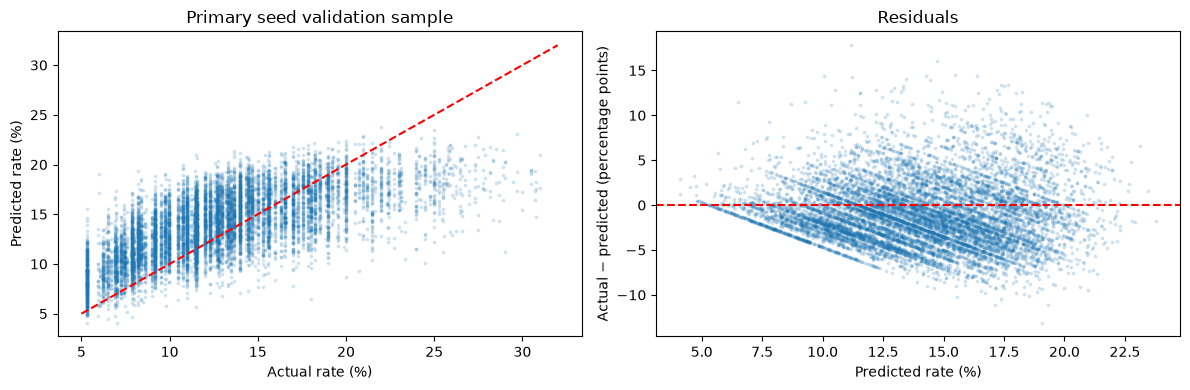

,n,mae,rmse,bias
issue_d,,,,
2015-01,35107.0,2.663235,3.259877,-1.187017
2015-02,23770.0,2.763798,3.368783,-1.403187
2015-03,25400.0,2.792850,3.400473,-1.502879
2015-04,35427.0,2.801645,3.424040,-1.424382
2015-05,31913.0,2.787841,3.417876,-1.389177
2015-06,28485.0,2.735022,3.356189,-1.344613
2015-07,45962.0,2.675806,3.268047,-1.315957
2015-08,35886.0,2.730886,3.321702,-1.459038
2015-09,28641.0,2.727395,3.333806,-1.414658


In [8]:
reg = pd.read_parquet(OUT / 'regression_seed42_validation_predictions.parquet')
reg['residual'] = reg.int_rate - reg.prediction
sample = reg.sample(n=10000, random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(sample.int_rate, sample.prediction, s=3, alpha=.15)
axes[0].plot([5, 32], [5, 32], '--', color='red')
axes[0].set(xlabel='Actual rate (%)', ylabel='Predicted rate (%)', title='Primary seed validation sample')
axes[1].scatter(sample.prediction, sample.residual, s=3, alpha=.15)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set(xlabel='Predicted rate (%)', ylabel='Actual − predicted (percentage points)', title='Residuals')
fig.tight_layout()
fig.savefig(FIG / 'regression_diagnostics.png', dpi=150)
plt.show()
monthly = reg.groupby(reg.issue_d.dt.to_period('M')).apply(lambda g: pd.Series(
    {'n': len(g), 'mae': g.residual.abs().mean(), 'rmse': np.sqrt(np.mean(g.residual ** 2)), 'bias': g.residual.mean()}))
monthly.to_csv(OUT / 'regression_monthly_errors.csv')
display(monthly)

## 10. Classification precision/recall, confusion, and the term-support gap

Report both minority classes separately. The audit found no 36-month At risk training examples but 4,586 in validation; a neural network cannot create those missing training examples. The term breakdown below evaluates performance without changing the class labels or adding observation-age inputs.

,precision,recall,f1-score,support
Good,0.859229,0.694561,0.768169,524595.00000
At risk,0.031619,0.463386,0.059199,9491.00000
Default,0.332188,0.265168,0.294918,144056.00000
accuracy,0.600110,0.600110,0.600110,0.60011
macro avg,0.407679,0.474372,0.374096,678142.00000
weighted avg,0.735688,0.600110,0.657715,678142.00000


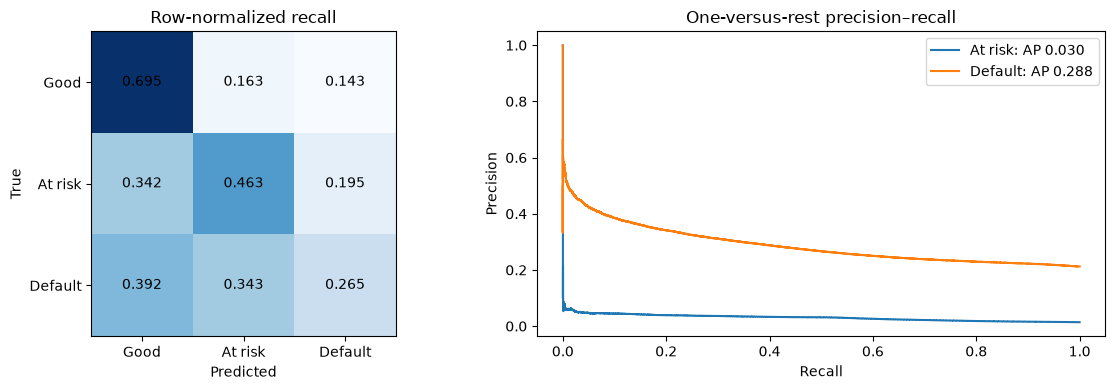

,term,n,at_risk_n,risk_ap,risk_recall
0,36.0,519973,4586,0.011467,0.000000
1,60.0,158169,4905,0.039217,0.896636


In [9]:
frame = pd.read_parquet(OUT / 'classification_seed42_validation_predictions.parquet')
report = pd.DataFrame(classification_report(frame.target_class, frame.prediction, labels=[0,1,2],
    target_names=['Good', 'At risk', 'Default'], zero_division=0, output_dict=True)).T
report.to_csv(OUT / 'classification_seed42_report.csv')
display(report)
matrix = confusion_matrix(frame.target_class, frame.prediction, labels=[0,1,2])
pd.DataFrame(matrix, index=['Good','At risk','Default'], columns=['Good','At risk','Default']).to_csv(OUT / 'classification_seed42_confusion.csv')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
values = matrix / matrix.sum(axis=1, keepdims=True)
axes[0].imshow(values, cmap='Blues')
for (i,j), value in np.ndenumerate(values):
    axes[0].text(j,i,f'{value:.3f}',ha='center',va='center')
axes[0].set(xticks=range(3),yticks=range(3),xticklabels=['Good','At risk','Default'],
            yticklabels=['Good','At risk','Default'],xlabel='Predicted',ylabel='True',title='Row-normalized recall')
for label, name in [(1,'At risk'),(2,'Default')]:
    y = frame.target_class.eq(label)
    precision, recall, _ = precision_recall_curve(y, frame[f'probability_{label}'])
    axes[1].plot(recall,precision,label=f'{name}: AP {average_precision_score(y,frame[f"probability_{label}"]):.3f}')
axes[1].set(xlabel='Recall',ylabel='Precision',title='One-versus-rest precision–recall')
axes[1].legend()
fig.tight_layout()
fig.savefig(FIG / 'classification_diagnostics.png', dpi=150)
plt.show()
terms = pd.read_parquet(PROJECT_ROOT / 'data/processed/accepted_classification_fe.parquet',
    columns=['issue_d','target_class','term'],filters=[('issue_d','>=',pd.Timestamp('2015-01-01')),('issue_d','<',pd.Timestamp('2017-01-01'))])
terms = terms.sort_values('issue_d',kind='stable').reset_index(drop=True)
np.testing.assert_array_equal(terms.target_class, frame.target_class)
term_rows=[]
for term, idx in terms.groupby('term').groups.items():
    y = frame.loc[idx,'target_class'].eq(1)
    term_rows.append({'term':term,'n':len(idx),'at_risk_n':int(y.sum()),
        'risk_ap':average_precision_score(y,frame.loc[idx,'probability_1']),
        'risk_recall':float(frame.loc[idx[y.to_numpy()],'prediction'].eq(1).mean())})
term_scores=pd.DataFrame(term_rows)
term_scores.to_csv(OUT / 'classification_seed42_term_scores.csv',index=False)
display(term_scores)

## 11. Interpretation, artifacts, and handoff

Each model directory contains a PyTorch state-dict checkpoint, fitted preprocessing, training bounds, and metadata. Checkpoints are loaded on CPU with `weights_only=True`; reload checks reproduce predictions. These models are fitted on the original training period only. Final train-plus-validation refitting and final test evaluation remain deferred until model choices are frozen.

Preserve retrospective-label, unequal-follow-up, selection-bias, term-support, and joint-applicant limitations. No performance gain establishes calibrated probabilities, fairness, or deployment readiness. Seed variability reflects the specified training randomness, not uncertainty from independent future portfolios.

In [10]:
reg_scores, cls_scores = results['regression'][2], results['classification'][2]
boost_reg = comparisons['regression'].query("model == 'hist_gradient_boosting'").iloc[0]
boost_cls = comparisons['classification'].query("model == 'hist_gradient_boosting'").iloc[0]
notes = f"""# Notebook 10 — observed deep-learning results

- Regression: validation RMSE **{reg_scores.rmse.mean():.3f} ± {reg_scores.rmse.std(ddof=1):.3f} percentage points** across training seeds; MAE **{reg_scores.mae.mean():.3f}**, R² **{reg_scores.r2.mean():.3f}**. Histogram boosting RMSE: **{boost_reg.rmse:.3f}**.
- Classification: validation macro F1 **{cls_scores.f1_macro.mean():.3f} ± {cls_scores.f1_macro.std(ddof=1):.3f}**, accuracy **{cls_scores.accuracy.mean():.2%}**, macro OVR AUC **{cls_scores.auc_macro_ovr.mean():.3f}**. Histogram boosting macro F1: **{boost_cls.f1_macro:.3f}**.
- At risk precision **{cls_scores.precision_class_1.mean():.2%}**, recall **{cls_scores.recall_class_1.mean():.2%}**, AP **{cls_scores.ap_class_1.mean():.4f}**. Default recall **{cls_scores.recall_class_2.mean():.2%}**. Read these alongside the confusion matrix and term-specific breakdown rather than accuracy alone.
- Every final classification model retained all **451,671 training loans**, including **611 At risk examples**. Regression used up to **50,000 seeded fitting rows**. All original validation rows were scored and their targets/dates matched previous notebooks.
- Epochs came from the final calendar month inside each fitting partition. Each scored model was freshly refitted on its full designated fitting partition after epoch selection; external validation did not determine stopping or seed choice.
- Numerical conditioning was an explicit training-fitted revision. Architectural and preprocessing/training-budget effects are not isolated by comparison with previous model families.
- Runtime: **{elapsed / 60:.2f} minutes**. Model save/reload checks passed. Original classes and external splits were preserved; final test data remain unread.
"""
display(Markdown(notes))
_ = (OUT / 'analysis.md').write_text(notes)

# Notebook 10 — observed deep-learning results

- Regression: validation RMSE **3.592 ± 0.022 percentage points** across training seeds; MAE **2.893**, R² **0.402**. Histogram boosting RMSE: **3.588**.
- Classification: validation macro F1 **0.371 ± 0.004**, accuracy **58.70%**, macro OVR AUC **0.653**. Histogram boosting macro F1: **0.422**.
- At risk precision **3.18%**, recall **47.47%**, AP **0.0305**. Default recall **27.80%**. Read these alongside the confusion matrix and term-specific breakdown rather than accuracy alone.
- Every final classification model retained all **451,671 training loans**, including **611 At risk examples**. Regression used up to **50,000 seeded fitting rows**. All original validation rows were scored and their targets/dates matched previous notebooks.
- Epochs came from the final calendar month inside each fitting partition. Each scored model was freshly refitted on its full designated fitting partition after epoch selection; external validation did not determine stopping or seed choice.
- Numerical conditioning was an explicit training-fitted revision. Architectural and preprocessing/training-budget effects are not isolated by comparison with previous model families.
- Runtime: **2.43 minutes**. Model save/reload checks passed. Original classes and external splits were preserved; final test data remain unread.


## 12. Assessment of the observed results

This executable assessment reads saved results and bundles without fitting models or changing selected settings.

In [1]:
from Python.deep_learning import NeuralModelBundle
reg_scores = pd.read_csv(OUT / 'regression_validation_scores.csv')
cls_scores = pd.read_csv(OUT / 'classification_validation_scores.csv')
previous_reg = pd.read_csv(PROJECT_ROOT / 'outputs/ensembles/regression_validation_scores.csv').query("model == 'hist_gradient_boosting'").iloc[0]
previous_cls = pd.read_csv(PROJECT_ROOT / 'outputs/ensembles/classification_validation_scores.csv').query("model == 'hist_gradient_boosting'").iloc[0]
term_scores = pd.read_csv(OUT / 'classification_seed42_term_scores.csv').set_index('term')
cards = []
for task in ['regression', 'classification']:
    task_scores = reg_scores if task == 'regression' else cls_scores
    for _, row in task_scores.iterrows():
        directory = OUT / 'models' / f'{task}_seed{int(row.seed)}'
        bundle = NeuralModelBundle.load(directory)
        names = bundle.preprocessing.preprocessor_._pipeline.named_steps['pre'].get_feature_names_out().tolist()
        card = {'task': task, 'seed': int(row.seed), 'parameters': json.loads(row.parameters),
                'selected_epochs': int(row.selected_epochs), 'n_training_rows': int(row.n_train),
                'encoded_feature_names': names,
                'parameter_count': sum(p.numel() for p in bundle.trainer.model_.parameters()),
                'regression_target_mean': bundle.trainer.target_mean_,
                'regression_target_scale': bundle.trainer.target_scale_,
                'class_weights': None if bundle.trainer.class_weights_ is None else bundle.trainer.class_weights_.tolist(),
                'prediction': 'NeuralModelBundle.load(directory).predict_frame(raw_allowlisted_data)',
                'output': 'Interest-rate percentage points' if task == 'regression' else 'Columns 0 Good, 1 At risk, 2 Default; weighted scores not calibrated population risk',
                'stage': 'Training-period development artifact; no final test assessment'}
        cards.append(card)
        _ = (directory / 'input_output_card.json').write_text(json.dumps(card, indent=2))
_ = (OUT / 'model_manifest.json').write_text(json.dumps(cards, indent=2))

extra = f"""
## Assessment of the observed results

**The MLP is a competitive regression reference, not a demonstrated improvement over boosting.** Its mean RMSE is {reg_scores.rmse.mean():.3f} percentage points versus {previous_reg.rmse:.3f} for boosting; the difference is much smaller than the MLP's training-seed spread ({reg_scores.rmse.std(ddof=1):.3f}). Selecting the best seed would exaggerate the comparison, so retain all three. Regression seed variation includes both the 50,000-row fitting sample and neural randomness. Numeric clipping/log transforms differ from previous model families, so this is not an isolated architecture comparison. Extreme rates are still compressed toward the middle, and monthly errors must be considered before generalizing to later vintages.

**The classification network does not replace the ensemble benchmark.** Mean macro F1 is {cls_scores.f1_macro.mean():.3f}, below boosting's {previous_cls.f1_macro:.3f}; mean Default recall is {cls_scores.recall_class_2.mean():.1%}, versus {previous_cls.recall_class_2:.1%}. Balanced loss selected by training CV increases At risk detection, but its mean precision is only {cls_scores.precision_class_1.mean():.2%} at recall {cls_scores.recall_class_1.mean():.1%}. Average precision is {cls_scores.ap_class_1.mean():.4f}, consistent with the weak ranking signal found in prior diagnostics. More At risk alerts alone are not evidence of an effective risk detector.

**The term-support gap persists.** For primary seed 42, At risk recall is {term_scores.loc[36, 'risk_recall']:.2%} for 36-month loans and {term_scores.loc[60, 'risk_recall']:.1%} for 60-month loans. The original training cohort has no 36-month At risk examples. A nonlinear model has not supplied the missing training support or established a common outcome horizon. Keep these findings alongside the overall confusion matrix.

**Early stopping is conservative and unstable for the rare-class task.** Final classification stopping chooses {int(cls_scores.selected_epochs.min())}–{int(cls_scores.selected_epochs.max())} epochs across seeds. The original training tail contains only 34 At risk cases; earlier CV inner fitting has as few as 13. Training loss can decrease while stopping loss rises. This indicates poor transfer to that stopping cohort; temporal prior changes, sparse minority support, weighting and model fitting can all contribute. It is not proof that every neural architecture would fail. The architecture, learning rates and weighting search are deliberately limited. A small selected epoch count is reported rather than hidden or replaced by validation-selected training duration.

**Protocol and artifacts:** every scored network is freshly refitted after selecting its epoch count within training data. All final classification models use all 451,671 training rows and all 611 At risk examples. Complete validation cohorts were retained, original classes/splits were preserved, and all six saved bundles reproduce predictions. Model/input/output cards and fitted bounds are saved for reproducible inference. Earlier models and the canonical predictor plans remain intact. The final test set is still reserved for the final comparison phase.

**Handoff:** retain boosting as the current classification benchmark and both boosting/MLP as regression references. Proceed with the required clustering notebook, then freeze choices before final test evaluation. The successful implementation satisfies the deep-learning comparison requirement; it does not establish calibration, fairness or deployment readiness.
"""
display(Markdown(extra))
analysis=OUT/'analysis.md'
base=analysis.read_text().split('\n## Assessment of the observed results')[0].rstrip()
_ = analysis.write_text(base+'\n'+extra)



## Assessment of the observed results

**The MLP is a competitive regression reference, not a demonstrated improvement over boosting.** Its mean RMSE is 3.592 percentage points versus 3.588 for boosting; the difference is much smaller than the MLP's training-seed spread (0.022). Selecting the best seed would exaggerate the comparison, so retain all three. Regression seed variation includes both the 50,000-row fitting sample and neural randomness. Numeric clipping/log transforms differ from previous model families, so this is not an isolated architecture comparison. Extreme rates are still compressed toward the middle, and monthly errors must be considered before generalizing to later vintages.

**The classification network does not replace the ensemble benchmark.** Mean macro F1 is 0.371, below boosting's 0.422; mean Default recall is 27.8%, versus 55.0%. Balanced loss selected by training CV increases At risk detection, but its mean precision is only 3.18% at recall 47.5%. Average precision is 0.0305, consistent with the weak ranking signal found in prior diagnostics. More At risk alerts alone are not evidence of an effective risk detector.

**The term-support gap persists.** For primary seed 42, At risk recall is 0.00% for 36-month loans and 89.7% for 60-month loans. The original training cohort has no 36-month At risk examples. A nonlinear model has not supplied the missing training support or established a common outcome horizon. Keep these findings alongside the overall confusion matrix.

**Early stopping is conservative and unstable for the rare-class task.** Final classification stopping chooses 1–3 epochs across seeds. The original training tail contains only 34 At risk cases; earlier CV inner fitting has as few as 13. Training loss can decrease while stopping loss rises. This indicates poor transfer to that stopping cohort; temporal prior changes, sparse minority support, weighting and model fitting can all contribute. It is not proof that every neural architecture would fail. The architecture, learning rates and weighting search are deliberately limited. A small selected epoch count is reported rather than hidden or replaced by validation-selected training duration.

**Protocol and artifacts:** every scored network is freshly refitted after selecting its epoch count within training data. All final classification models use all 451,671 training rows and all 611 At risk examples. Complete validation cohorts were retained, original classes/splits were preserved, and all six saved bundles reproduce predictions. Model/input/output cards and fitted bounds are saved for reproducible inference. Earlier models and the canonical predictor plans remain intact. The final test set is still reserved for the final comparison phase.

**Handoff:** retain boosting as the current classification benchmark and both boosting/MLP as regression references. Proceed with the required clustering notebook, then freeze choices before final test evaluation. The successful implementation satisfies the deep-learning comparison requirement; it does not establish calibration, fairness or deployment readiness.
